# LSTM: Market Volatility Forecasting

Predict the magnitude of market fluctuations over the next five trading sessions from 60 past sessions. An LSTM learns a correction to trailing historical volatility. This model forecasts volatility, not price direction or trading returns.

In [1]:
from pathlib import Path
import sys, json, inspect
ROOT = Path.cwd() if (Path.cwd() / 'examples').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import jax
import numpy as np
import pandas as pd
import neuraljaxlib as nj
from neuraljaxlib import checkpoint
from examples.forecasting import ForecastModel, train_step, infer, decode
from IPython.display import display, Image, Code
RUN = ROOT / 'runs/forecast-gallery-v2/lstm'
print(f"NeuralJAXlib {nj.__version__} · JAX {jax.__version__}")
print(jax.devices())

NeuralJAXlib 0.1.0 · JAX 0.5.3


[CudaDevice(id=0)]


## Data and forecasting target

Daily S&P 500 closing index values come from [FRED series SP500](https://fred.stlouisfed.org/series/SP500), sourced from S&P Dow Jones Indices LLC. The cached snapshot covers October 2016–December 2025; FRED exposes a rolling history, so later downloads may start at a different date. The source URL, exact file hash, and split dates are recorded below. Source data terms are separate from the package license.

Let $r_t=\log(P_t/P_{t-1})$. At the close of session $t$, the target is $\sqrt{252\,\mathrm{mean}(r_{t+1:t+5}^2)}$: the annualized root-mean-square return over the next five sessions. This is a realized-volatility proxy, not centered sample standard deviation.

The input contains 60 known returns, absolute returns, and trailing 5- and 20-session volatility. The loss is MSE in standardized log-volatility space; mean and scale are fitted only to training targets. Trailing volatility uses past returns only. Baselines use the latest trailing 5- or 20-session value.

## Chronological evaluation

Training targets end before 2023; validation targets fall within 2023; test targets fall within 2024–2025. Windows whose targets cross a split boundary are excluded. A validation or test forecast may use earlier observations as history, just as at inference time. No future observation enters its input.

The training loader shuffles complete windows, but the split is chronological. Validation loss selects the checkpoint and controls early stopping (15 epochs without improvement). Test data are evaluated after checkpoint selection.

Adjacent market targets overlap over five sessions. Reported errors are descriptive; they are not independent statistical trials.

## Architecture

Input `[B,60,4]` → LSTM with 16 hidden units → one correction in standardized log-volatility space. Add the correction to the latest trailing-20-session baseline, then invert the transform.

The output projection starts at zero, so the initial model equals its baseline. Training learns how to adjust it. The same `nn.Module` composition and explicit optimizer API used in the other tutorials apply here.

In [2]:
display(Code(inspect.getsource(ForecastModel), language="python"))

class ForecastModel(nn.Module):
    """Learn a recurrent correction to an available historical baseline."""

    def __init__(self, task, hidden=32, *, rngs):
        super().__init__()
        self.task = task
        self.sequence = models.SequenceRegressor(
            features=5 if task == "rnn" else 4,
            hidden=hidden,
            outputs=24 if task == "rnn" else 1,
            kind=task,
            rngs=rngs,
        )
        self.sequence.head.weight.value = jnp.zeros_like(self.sequence.head.weight.value)
        self.sequence.head.bias.value = jnp.zeros_like(self.sequence.head.bias.value)

    def forward(self, x):
        # Use full float32 products consistently across GPU compilation contexts.
        with jax.default_matmul_precision("highest"):
            correction = self.sequence(x)["prediction"]
        baseline = x[:, -24:, 0] if self.task == "rnn" else x[:, -1, -1:]
        return baseline + correction

## Objective and optimization

AdamW uses learning rate 0.001 and weight decay 0.001. Gradient norms are clipped to 1.0. Model state and optimizer state are explicit compiled-step arguments.

In [3]:
display(Code(inspect.getsource(train_step), language="python"))

@nj.jit
def train_step(model, optimizer, x, y):
    loss, grads = nj.value_and_grad(lambda candidate: F.mse_loss(candidate(x), y))(model)
    grads, norm = optim.clip_grad_norm(grads, 1.0)
    optimizer.step(grads)
    return loss, norm

## Reproduce the run

Select GPU 0 before starting Python or Jupyter: `CUDA_VISIBLE_DEVICES=0`. The published notebook displays saved outputs. To reproduce locally, set `TRAIN=True` and choose a fresh `RUN` directory; the command downloads missing data explicitly. Existing runs are preserved. Full training and notebook execution are local-only; CI renders saved outputs.

In [4]:
from examples.train_gallery import RECIPES
import subprocess
TRAIN = False
command = [sys.executable, '-m', 'examples.run', 'lstm', '--download',
           '--output', str(RUN), *RECIPES['lstm']]
print(' '.join(part.replace(str(ROOT) + '/', '')
               for part in ['python', *command[1:]]))
if TRAIN:
    subprocess.run(command, cwd=ROOT, check=True)
if not (RUN / 'report.json').exists():
    raise FileNotFoundError('Set TRAIN=True with a fresh RUN directory to reproduce the experiment.')
report = json.loads((RUN / 'report.json').read_text())
metadata = json.loads((RUN / 'data.json').read_text())
display(pd.DataFrame([report['config']]))
display(pd.DataFrame({split: metadata[split] for split in ('train', 'validation', 'test')}).T)
print('Source SHA-256:', metadata['source_sha256'])
print('Training devices:', ', '.join(report['devices']))
print('Target normalization:', metadata['target_mean'], metadata['target_scale'])

python -m examples.run lstm --download --output runs/forecast-gallery-v2/lstm --epochs 80 --limit 100000 --batch-size 64 --model-width 16


,task,epochs,batch_size,limit,seed,hidden,patience,learning_rate,matmul_precision
0,lstm,80,64,100000,0,16,15,0.001,highest


,count,first_origin,last_origin
train,1479,2017-02-10,2022-12-23
validation,246,2023-01-03,2023-12-22
test,498,2024-01-02,2025-12-24


Source SHA-256: 4f867010611c46759a39295ac0d45d3e5d000e127546a288d6b9cdb585ed00ee
Training devices: cuda:0 NVIDIA GeForce RTX 5090
Target normalization: -2.130350205968994 0.7122885429625886


## Training history

The curve shows training and validation MSE in normalized target space. The selected checkpoint is the epoch with the lowest validation loss, not necessarily the last epoch.

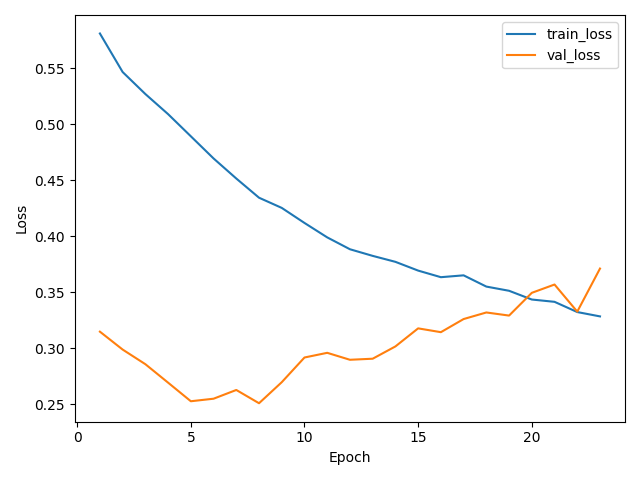

Selected epoch: 8
Completed epochs: 23


In [5]:
display(Image(filename=str(RUN / 'learning.png')))
print('Selected epoch:', report['selected_epoch'])
print('Completed epochs:', len(report['history']))

## Held-out evaluation

MAE and RMSE below are expressed in annualized volatility percentage points. Log-RMSE uses natural-log volatility. Each origin contributes one five-session target.

In [6]:
scores = pd.DataFrame(report['evaluation']).T
scores[['mae', 'rmse']] *= 100
display(scores.rename(columns={'mae': 'MAE', 'rmse': 'RMSE', 'log_rmse': 'Log-RMSE'}).round(4))

,MAE,RMSE,Log-RMSE
model,4.5637,7.9668,0.4426
baseline_5d,5.6909,9.3893,0.5499
baseline_20d,5.6981,9.6293,0.5217


## Forecasts through time

The upper panel shows the known S&P 500 closing level. The lower panel compares the forecast with subsequent realized volatility and the trailing-20-session baseline. All held-out origins are shown. The model improves average error in this run but underestimates the sharp April 2025 spike; historical inputs cannot anticipate every abrupt event. The gray future outcome is aligned to its forecast start date and becomes known only after five sessions.

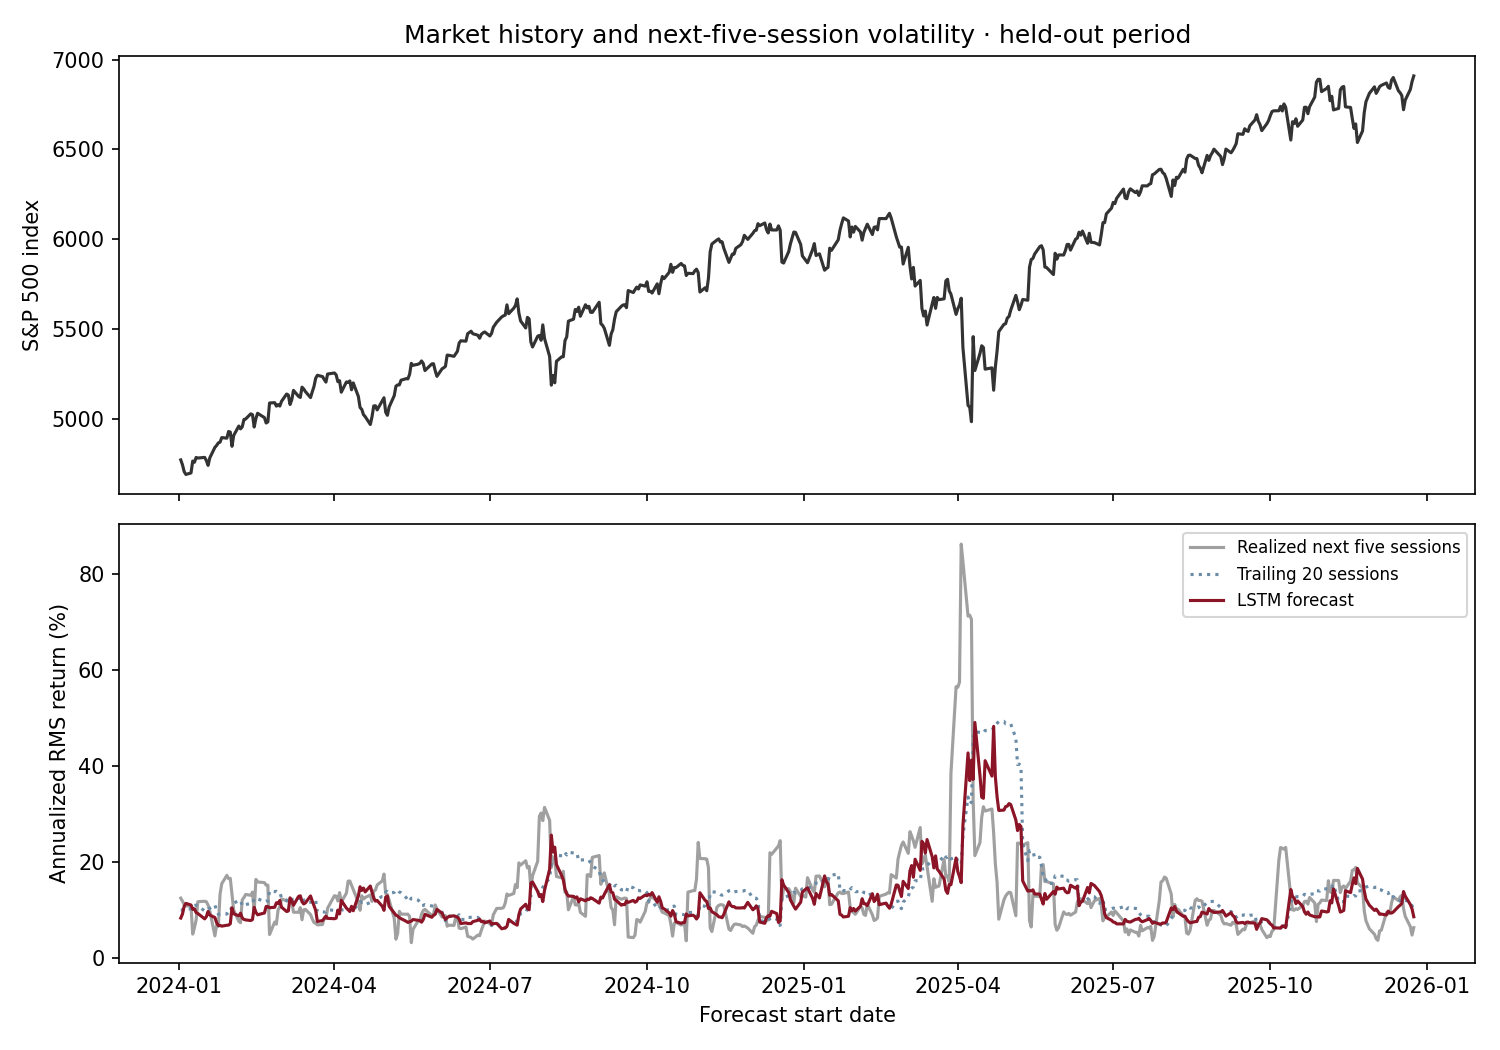

In [7]:
display(Image(filename=str(RUN / 'forecast.png')))

## Restore the model and reproduce predictions

Load the selected checkpoint into the same architecture. The comparison below checks inference against the saved prediction records.

In [8]:
with np.load(RUN / 'predictions.npz', allow_pickle=False) as archive:
    records = {name: archive[name] for name in archive.files}
model = ForecastModel('lstm', hidden=report['config']['hidden'], rngs=nj.Rngs(params=0))
checkpoint.restore(RUN / 'best.npz', model=model)
model.eval()
replayed = decode(infer(model, records['inputs'][:64], batch_size=64), metadata)
np.testing.assert_allclose(replayed, records['predictions'][:64], rtol=1e-5, atol=1e-5)
print('Saved predictions reproduced from the checkpoint.')
display(pd.DataFrame({'Issued after': records['issued_at'][:5],
                      'Forecast begins': records['origins'][:5],
                      'Outcome available': records['outcome_available_at'][:5]}))

Saved predictions reproduced from the checkpoint.


,Issued after,Forecast begins,Outcome available
0,2023-12-29,2024-01-02,2024-01-08
1,2024-01-02,2024-01-03,2024-01-09
2,2024-01-03,2024-01-04,2024-01-10
3,2024-01-04,2024-01-05,2024-01-11
4,2024-01-05,2024-01-08,2024-01-12


## Visualization artifacts

`predictions.npz` retains every held-out forecast, baseline, target, input window, and timestamp. `visualization.json` describes the fields. `issued_at` marks the final known observation; `outcome_available_at` marks when the full target can be revealed. `history` contains index levels for the price panel; `history_returns` contains the known returns. Volatility arrays store fractions; multiply by 100 for percentage labels. `future_prices` are held-out outcomes and must not be shown as known history before their timestamps.

These records support a rolling square animation without retraining. Checkpoints, source data, and full prediction arrays remain local and gitignored. The notebook embeds the evaluated plots and metrics. This is a single-seed demonstration; improvements over these baselines do not establish performance across cities, market periods, or model configurations.